# EECE5644 Recitation: Naive Bayes Classifiers
### Heart-disease diagnosis with continuous, categorical, binary, and mixed features

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import logsumexp
from scipy.stats import norm
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, CategoricalNB, BernoulliNB
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix
from IPython.display import display

# Fixed seeds make the classroom demonstration reproducible.
SEED = 42
COLORS = ['#2676b8', '#d65e32']
CLASS_NAMES = ['No disease (0)', 'Disease (1)']
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titlesize': 12, 'figure.facecolor': 'white'
})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', None)

## 1. The problem: heart-disease diagnosis

A patient is referred to a cardiology clinic. From routine measurements, an exercise
test, and two imaging tests, **should the patient be flagged for heart disease?**

**Dataset:** *Statlog (Heart)* from the UCI repository, loaded from OpenML
(`data_id=53`, cached after the first run). One row = one patient; 270 patients, no
missing values. **Label** `class`: heart disease `absent` (150, `y = 0`) or `present`
(120, 44%, `y = 1`). **Features:** 13 measurements of three types:

| `X_mixed` column | Block, index $j$ | Column in the data | Meaning | Values |
|---:|---|---|---|---|
| 0 | continuous, $j=0$ | `age` | Age | 29–77 years |
| 1 | continuous, $j=1$ | `resting_blood_pressure` | Blood pressure at rest | 94–200 mm Hg |
| 2 | continuous, $j=2$ | `serum_cholestoral` | Cholesterol in the blood | 126–564 mg/dl |
| 3 | continuous, $j=3$ | `maximum_heart_rate_achieved` | Highest heart rate in the exercise test | 71–202 bpm |
| 4 | continuous, $j=4$ | `oldpeak` | ST depression during exercise, relative to rest | 0–6.2 mm; exactly 0 for 31% |
| 5 | categorical, $j=0$ | `chest` | Chest-pain type | 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| 6 | categorical, $j=1$ | `resting_electrocardiographic_results` | Resting ECG | 0 normal, 1 ST-T abnormality, 2 LV hypertrophy (thickened heart wall) |
| 7 | categorical, $j=2$ | `slope` | Shape of the ST segment at peak exercise | 1 upsloping, 2 flat, 3 downsloping |
| 8 | categorical, $j=3$ | `number_of_major_vessels` | Major vessels colored by fluoroscopy | 0, 1, 2, 3 |
| 9 | categorical, $j=4$ | `thal` | Thallium stress test | 3 normal, 6 fixed defect, 7 reversible defect |
| 10 | binary, $j=0$ | `sex` | Sex | 1 male, 0 female |
| 11 | binary, $j=1$ | `fasting_blood_sugar` | Fasting blood sugar > 120 mg/dl | 1 yes, 0 no |
| 12 | binary, $j=2$ | `exercise_induced_angina` | Chest pain during the exercise test | 1 yes, 0 no |

**Medical terms in brief**
- **Angina:** chest pain from too little blood flow to the heart muscle. *Typical*: the
  classic pattern (brought on by exertion, relieved by rest); *atypical*: part of it;
  *non-anginal*: probably not from the heart; *asymptomatic*: no chest pain.
- **ST segment:** part of each heartbeat on the ECG. When the heart muscle lacks blood
  during exercise, it often drops (ST depression, `oldpeak`) and becomes flat or
  downsloping (`slope`).
- **Imaging:** fluoroscopy is X-ray imaging with dye. The thallium test images blood flow
  to the heart muscle: a *fixed defect* has poor flow at rest and under stress (e.g.
  scar), a *reversible defect* only under stress.

**In code:** `X_mixed` (270 × 13) has the columns in the order above, and `X_cont`,
`X_cat`, `X_bin` are its three blocks. **Inside a block, $j$ restarts at 0**; every
parameter below is indexed by the class $c$ and this $j$. The categorical codes are
labels, not quantities, and `CategoricalNB` needs them numbered $k=0,\ldots,K_j-1$, so
`encode` replaces each code by its position in the Values column (e.g. thal 3, 6, 7 →
$k$ = 0, 1, 2).

We also follow one **new patient** (not one of the 270) through Parts 4 to 6.

In [2]:
heart = fetch_openml(data_id=53, as_frame=True).frame  # Statlog (Heart), 270 patients.

continuous = ['age', 'resting_blood_pressure', 'serum_cholestoral',
              'maximum_heart_rate_achieved', 'oldpeak']
# Known codes and meanings of each categorical feature (from the dataset documentation).
categorical = {
    'chest': {1: 'typical angina', 2: 'atypical angina', 3: 'non-anginal pain', 4: 'asymptomatic'},
    'resting_electrocardiographic_results': {0: 'normal', 1: 'ST-T abnormality', 2: 'LV hypertrophy'},
    'slope': {1: 'upsloping', 2: 'flat', 3: 'downsloping'},  # ST segment during exercise
    'number_of_major_vessels': {0: '0', 1: '1', 2: '2', 3: '3'},
    'thal': {3: 'normal', 6: 'fixed defect', 7: 'reversible defect'}
}
binary = ['sex', 'fasting_blood_sugar', 'exercise_induced_angina']  # sex: 1 = male

def encode(frame):
    """Raw patient table -> numeric matrix with columns [continuous | categorical | binary].
    Each category code is replaced by its position k = 0, ..., K-1."""
    positions = np.column_stack([
        frame[col].map({code: k for k, code in enumerate(meanings)}) for col, meanings in categorical.items()
    ])
    assert not np.isnan(positions).any(), 'A category code is missing from the known codes.'
    return np.column_stack([frame[continuous].to_numpy(float), positions, frame[binary].to_numpy(float)])

X_mixed = encode(heart)
y = (heart['class'] == 'present').to_numpy().astype(int)
cols_cont, cols_cat, cols_bin = list(range(0, 5)), list(range(5, 10)), list(range(10, 13))
X_cont = X_mixed[:, cols_cont]
X_cat = X_mixed[:, cols_cat].astype(int)
X_bin = X_mixed[:, cols_bin].astype(int)
category_sizes = [len(meanings) for meanings in categorical.values()]  # K_j: known schema, not inferred.

# Short feature names in X_mixed column order; every table below uses them.
feature_names = ['age', 'resting BP', 'cholesterol', 'max heart rate', 'ST depression',
                 'chest pain', 'resting ECG', 'ST slope', 'major vessels', 'thal',
                 'male', 'fasting blood sugar > 120', 'exercise angina']
units = ['years', 'mm Hg', 'mg/dl', 'bpm', 'mm']  # Units of the five continuous features.

def readable(raw):
    """One raw patient row -> 'feature = value' strings, in X_mixed column order."""
    return ([f'{name} = {float(raw[col]):g} {unit}'
             for name, col, unit in zip(feature_names[:5], continuous, units)]
            + [f'{name} = {categorical[col][int(raw[col])]}'
               for name, col in zip(feature_names[5:10], categorical)]
            + [f'{name} = {"yes" if raw[col] == 1 else "no"}'
               for name, col in zip(feature_names[10:], binary)])

display(heart.head())
print(f'{len(y)} patients, {y.sum()} with heart disease ({y.mean():.0%})')

# The new patient, written with the same raw codes as the data.
new_patient_raw = pd.DataFrame([{
    'age': 62, 'sex': 1, 'chest': 3, 'resting_blood_pressure': 150, 'serum_cholestoral': 280,
    'fasting_blood_sugar': 0, 'resting_electrocardiographic_results': 2,
    'maximum_heart_rate_achieved': 130, 'exercise_induced_angina': 1, 'oldpeak': 0.4,
    'slope': 1, 'number_of_major_vessels': 1, 'thal': 3
}])
new_patient = encode(new_patient_raw)  # Shape (1, 13), same columns as X_mixed.
new_text = readable(new_patient_raw.iloc[0])
print('\nNew patient')
for block, columns in [('continuous', cols_cont), ('categorical', cols_cat), ('binary', cols_bin)]:
    print(f'  {block:11s}: ' + '; '.join(new_text[col] for col in columns))

,age,sex,chest,resting_blood_pressure,serum_cholestoral,fasting_blood_sugar,resting_electrocardiographic_results,maximum_heart_rate_achieved,exercise_induced_angina,oldpeak,slope,number_of_major_vessels,thal,class
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,present
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,absent
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,present
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,absent
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,absent


270 patients, 120 with heart disease (44%)

New patient
  continuous : age = 62 years; resting BP = 150 mm Hg; cholesterol = 280 mg/dl; max heart rate = 130 bpm; ST depression = 0.4 mm
  categorical: chest pain = non-anginal pain; resting ECG = LV hypertrophy; ST slope = upsloping; major vessels = 1; thal = normal
  binary     : male = yes; fasting blood sugar > 120 = no; exercise angina = yes


## 2. Bayes' rule with different likelihoods
For a patient with features $x$ and a class $c$,

$$P(y=c\mid x)\propto P(y=c)\,p(x\mid y=c).$$

Naive Bayes assumes the features are **conditionally independent given the class**,
$p(x\mid y=c)=\prod_{j}p(x_j\mid y=c)$. Here: given the diagnosis, the 13 measurements
are treated as independent, which is only an approximation (age and maximum heart rate
are related, for example). With logarithms,

$$s_c(x)=\log\pi_c+\sum_{j}\log p(x_j\mid y=c),\qquad \hat y=\arg\max_c s_c(x),$$

and the posteriors are the normalized scores,
$P(y=c\mid x)=\exp\left(s_c(x)-\operatorname{logsumexp}_{c'}s_{c'}(x)\right)$.

| Symbol | Here | In code |
|---|---|---|
| $y$, $c$ | Diagnosis / one class: 0 = no disease, 1 = disease | `y`; the row index of every parameter array |
| $x$, $x_j$ | The 13 features of one patient / one of them | one row of `X_mixed` / one column of a block |
| $\pi_c$ | Prior $P(y=c)$, before any feature is seen | `class_prior_` |

Only $p(x_j\mid y=c)$ changes with the feature type:

| Feature type | Likelihood | scikit-learn estimator |
|---|---|---|
| Continuous, e.g. maximum heart rate | One Gaussian density per feature and class | `GaussianNB` |
| Categorical, e.g. chest-pain type | One probability table per feature and class | `CategoricalNB` |
| Binary, e.g. exercise-induced angina | One Bernoulli probability per feature and class | `BernoulliNB` |
| A mixture of the above | Add the log likelihoods of all feature blocks | Part 6 |

In [3]:
def probabilities_from_scores(scores):
    """Normalize log class scores (rows = samples, columns = classes) into posteriors."""
    return np.exp(scores - logsumexp(scores, axis=1, keepdims=True))

## 3. Cut the data into train, validation, and test
The patients are split **once**, and every model below reuses the same rows:

| Subset | Patients | Job |
|---|---:|---|
| Train (60%) | 162 | Fit the parameters: means, variances, probability tables, priors |
| Validation (20%) | 54 | Choose α, the prior, and the model |
| Test (20%) | 54 | Report performance after all choices are fixed |

`stratify=y` keeps the disease fraction (44%) equal in each subset. The training rows
contain $N_0=90$ patients without and $N_1=72$ with heart disease.

In [4]:
n = len(y)
# First hold out 20% for test; then reserve 25% of the remaining 80% for validation.
train_val_idx, test_idx = train_test_split(
    np.arange(n), test_size=0.20, stratify=y, random_state=SEED
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.25, stratify=y[train_val_idx], random_state=SEED + 1
)
display(pd.DataFrame([
    {'subset': name, 'patients': len(idx), 'no disease (c=0)': np.sum(y[idx] == 0),
     'disease (c=1)': np.sum(y[idx] == 1)}
    for name, idx in {'train': train_idx, 'validation': val_idx, 'test': test_idx}.items()
]))
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == n  # Disjoint and complete.

,subset,patients,no disease (c=0),disease (c=1)
0,train,162,90,72
1,validation,54,30,24
2,test,54,30,24


## 4. Continuous features: Gaussian NB
For class $c$ and continuous feature $j$,

$$p(x_j\mid y=c)=\frac{1}{\sqrt{2\pi\sigma_{cj}^{2}}}
\exp\left[-\frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^{2}}\right].$$

| Symbol | Attribute | Shape | Meaning here |
|---|---|---|---|
| $\mu_{cj}$ | `theta_[c, j]` | (2, 5) | Average of feature $j$ over the training patients of class $c$ |
| $\sigma^2_{cj}$ | `var_[c, j]` | (2, 5) | Variance of feature $j$ over the same patients |

Rows $c$: 0 no disease, 1 disease. Columns $j$: 0 age, 1 resting BP, 2 cholesterol,
3 maximum heart rate, 4 ST depression. For example, `theta_[1, 3]` is the average
maximum heart rate of the training patients with disease.

```python
model = GaussianNB(priors=None)   # None: learn class proportions from the training data
model.fit(X_train, y_train)
probabilities = model.predict_proba(X_new)
```

In [5]:
gnb_demo = GaussianNB().fit(X_cont[train_idx], y[train_idx])

# theta_ and var_ are just the per-class sample means and variances of each feature.
X_train, y_train = X_cont[train_idx], y[train_idx]
for c in [0, 1]:
    assert np.allclose(gnb_demo.theta_[c], X_train[y_train == c].mean(axis=0))
    assert np.allclose(gnb_demo.var_[c], X_train[y_train == c].var(axis=0))

print('class_prior_ = [pi_0, pi_1] =', gnb_demo.class_prior_.round(3))
display(pd.DataFrame({
    'unit': units,
    'mu_0j': gnb_demo.theta_[0], 'mu_1j': gnb_demo.theta_[1],
    'sigma_0j': np.sqrt(gnb_demo.var_[0]), 'sigma_1j': np.sqrt(gnb_demo.var_[1])
}, index=pd.Index([f'{j}: {name}' for j, name in enumerate(feature_names[:5])], name='feature j')).round(2))

def gaussian_log_likelihood(model, X):
    """Return log p(X | class), excluding the class prior; shape (rows, classes)."""
    X = np.asarray(X)
    difference = X[:, None, :] - model.theta_[None, :, :]
    # Sum over features; do not sum over classes or samples.
    return -0.5 * (
        np.log(2 * np.pi * model.var_)[None, :, :]
        + difference**2 / model.var_[None, :, :]
    ).sum(axis=2)

new_cont = new_patient[:, cols_cont]
manual_probability = probabilities_from_scores(
    gaussian_log_likelihood(gnb_demo, new_cont) + np.log(gnb_demo.class_prior_)
)
print('New patient, continuous features only: P(no disease), P(disease) =', manual_probability.round(4))
assert np.allclose(manual_probability, gnb_demo.predict_proba(new_cont))

class_prior_ = [pi_0, pi_1] = [0.556 0.444]


,unit,mu_0j,mu_1j,sigma_0j,sigma_1j
feature j,,,,,
0: age,years,52.30,56.56,9.77,7.85
1: resting BP,mm Hg,129.68,136.08,16.43,18.24
2: cholesterol,mg/dl,243.98,253.64,56.91,49.96
3: max heart rate,bpm,159.97,139.93,19.71,20.82
4: ST depression,mm,0.61,1.60,0.83,1.24


New patient, continuous features only: P(no disease), P(disease) = [[0.2779 0.7221]]


**Left two panels:** histogram and fitted Gaussian per class for $j=3$ (maximum heart
rate) and $j=4$ (ST depression). Maximum heart rate looks roughly Gaussian. ST depression
does not: many patients have exactly 0 and the rest form a long tail, yet Gaussian NB
still uses one Gaussian per class. The Gaussian shape is an **assumption**.

**Right:** the posterior from these two features alone. The product of the two 1-D
Gaussians is a 2-D Gaussian with **diagonal covariance**; because the classes have
different variances, the 0.5 boundary is curved. The star is the new patient.

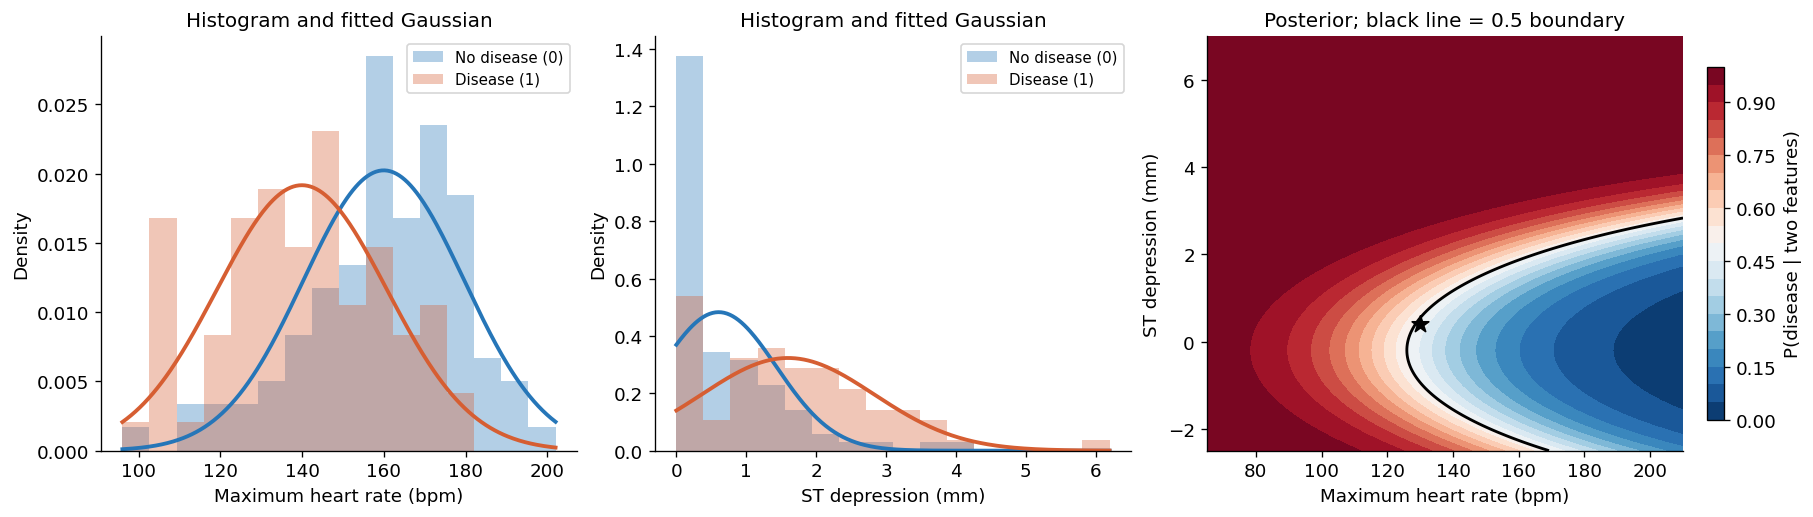

In [6]:
j_hr, j_st = 3, 4  # Maximum heart rate and ST depression inside X_cont.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout='constrained')
for ax, j, label in zip(axes[:2], [j_hr, j_st], ['Maximum heart rate (bpm)', 'ST depression (mm)']):
    values = X_cont[train_idx, j]
    edges = np.histogram_bin_edges(values, bins=16)
    xs = np.linspace(edges[0], edges[-1], 300)
    for c, color in enumerate(COLORS):
        ax.hist(values[y[train_idx] == c], bins=edges, density=True, alpha=0.35,
                color=color, label=CLASS_NAMES[c])
        ax.plot(xs, norm.pdf(xs, gnb_demo.theta_[c, j], np.sqrt(gnb_demo.var_[c, j])), color=color, lw=2.3)
    ax.set(xlabel=label, ylabel='Density', title='Histogram and fitted Gaussian')
    ax.legend(fontsize=9)

# A meshgrid evaluates the two-feature posterior at many possible readings.
gnb_pair = GaussianNB().fit(X_cont[train_idx][:, [j_hr, j_st]], y[train_idx])
xx, yy = np.meshgrid(np.linspace(65, 210, 200), np.linspace(-2.5, 7, 200))
posterior_grid = gnb_pair.predict_proba(np.column_stack([xx.ravel(), yy.ravel()]))[:, 1].reshape(xx.shape)
image = axes[2].contourf(xx, yy, posterior_grid, levels=np.linspace(0, 1, 21), cmap='RdBu_r', vmin=0, vmax=1)
axes[2].contour(xx, yy, posterior_grid, levels=[0.5], colors='black', linewidths=1.7)
axes[2].scatter(*new_cont[0, [j_hr, j_st]], s=110, marker='*', color='black')
axes[2].set(title='Posterior; black line = 0.5 boundary',
            xlabel='Maximum heart rate (bpm)', ylabel='ST depression (mm)')
fig.colorbar(image, ax=axes[2], label='P(disease | two features)', shrink=0.85)
plt.show()

## 5. Categorical and binary features
### Categorical NB: one probability table per feature
For category $k$ of categorical feature $j$,

$$P(x_j=k\mid y=c)=\frac{N_{cjk}+\alpha}{N_c+\alpha K_j}.$$

| Symbol | Attribute | Meaning here |
|---|---|---|
| $j$ | column of `X_cat` | 0 chest pain, 1 resting ECG, 2 ST slope, 3 major vessels, 4 thal |
| $K_j$ | `min_categories[j]` | Number of categories: 4, 3, 3, 4, 3 |
| $N_c$ | `class_count_[c]` | Training patients in class $c$: 90 and 72 |
| $N_{cjk}$ | `category_count_[j][c, k]` | Training patients of class $c$ whose feature $j$ is category $k$ |
| $P(x_j=k\mid y=c)$ | `np.exp(feature_log_prob_[j][c, k])` | The smoothed table entry |

`feature_log_prob_` is a list of 5 arrays, one per feature; array $j$ has shape
$(2, K_j)$ and each row sums to 1.

**Why smoothing?** In our training rows, resting ECG ($j=1$) = *ST-T abnormality*
($k=1$) occurs once, in a patient with disease, and never without: $N_{0,1,1}=0$. With
$\alpha=0$, every future patient with this ECG would get $P(\text{disease})=1$ from a
single training patient. $\alpha=1$ is Laplace smoothing; a large $\alpha$ pushes every
table toward uniform.

**Two different hyperparameters:** $\alpha$ smooths the feature probabilities; the
class prior $\pi_c$ is the probability of each class before seeing any features.

In [7]:
def smoothed_category_probabilities(counts, alpha):
    """Add alpha to each category and renormalize each class row."""
    K = counts.shape[1]
    return (counts + alpha) / (counts.sum(axis=1, keepdims=True) + alpha * K)

# N_cjk for j = 1 (resting ECG): rows = class c, columns = category k.
ecg_counts = np.array([np.bincount(X_cat[train_idx][y[train_idx] == c, 1], minlength=3) for c in [0, 1]])
display(pd.DataFrame(ecg_counts, index=CLASS_NAMES,
                     columns=['k=0: normal', 'k=1: ST-T abnormality', 'k=2: LV hypertrophy']))

rows = []
for alpha in [0.0, 1.0, 10.0, 100.0]:
    probability = smoothed_category_probabilities(ecg_counts, alpha)
    joint = 0.5 * probability[:, 1]  # Equal class priors; observe only ST-T abnormality.
    rows.append({'alpha': alpha, 'P(ST-T | no disease)': probability[0, 1],
                 'P(ST-T | disease)': probability[1, 1], 'P(disease | ST-T)': joint[1] / joint.sum()})
display(pd.DataFrame(rows).round(4))

,k=0: normal,k=1: ST-T abnormality,k=2: LV hypertrophy
No disease (0),49,0,41
Disease (1),24,1,47


,alpha,P(ST-T | no disease),P(ST-T | disease),P(disease | ST-T)
0,0.0,0.0000,0.0139,1.0000
1,1.0,0.0108,0.0267,0.7126
2,10.0,0.0833,0.1078,0.5641
3,100.0,0.2564,0.2715,0.5143


#### Fit Categorical NB on all five categorical features
```python
model = CategoricalNB(alpha=1.0, class_prior=None, min_categories=[4, 3, 3, 4, 3])
model.fit(X_train_category_positions, y_train)
```
`min_categories` declares $K_j$, so a category missing from the training rows still gets
a smoothed probability. The table lists $N_{0jk}$, $N_{1jk}$, and the table entries for
every feature $j$ and category $k$.

In [8]:
cat_demo = CategoricalNB(alpha=1.0, min_categories=category_sizes)
cat_demo.fit(X_cat[train_idx], y[train_idx])

def categorical_log_likelihood(model, X):
    """Look up one category probability per feature, then add the log values."""
    X = np.asarray(X, dtype=int)
    scores = np.zeros((len(X), len(model.classes_)))
    for j, log_table in enumerate(model.feature_log_prob_):
        scores += log_table[:, X[:, j]].T
    return scores  # Prior intentionally excluded so it can be added exactly once.

rows = []
for j, meanings in enumerate(categorical.values()):
    counts = cat_demo.category_count_[j]                 # N_cjk, shape (2, K_j)
    probability = np.exp(cat_demo.feature_log_prob_[j])  # P(x_j = k | c), shape (2, K_j)
    assert np.allclose(probability, smoothed_category_probabilities(counts, cat_demo.alpha))
    for k, meaning in enumerate(meanings.values()):
        rows.append({'feature j': f'{j}: {feature_names[5 + j]}', 'category k': f'{k}: {meaning}',
                     'N_0jk': int(counts[0, k]), 'N_1jk': int(counts[1, k]),
                     'P(k | no disease)': probability[0, k], 'P(k | disease)': probability[1, k]})
display(pd.DataFrame(rows).set_index(['feature j', 'category k']).round(3))

new_cat = new_patient[:, cols_cat].astype(int)
cat_probability = probabilities_from_scores(categorical_log_likelihood(cat_demo, new_cat) + cat_demo.class_log_prior_)
print('New patient, categorical features only: P(no disease), P(disease) =', cat_probability.round(4))
assert np.allclose(cat_probability, cat_demo.predict_proba(new_cat))

N_0jk  N_1jk  P(k | no disease)  \
feature j        category k                                              
0: chest pain    0: typical angina        12      4              0.138   
                 1: atypical angina       25      4              0.277   
                 2: non-anginal pain      41     11              0.447   
                 3: asymptomatic          12     53              0.138   
1: resting ECG   0: normal                49     24              0.538   
                 1: ST-T abnormality       0      1              0.011   
                 2: LV hypertrophy        41     47              0.452   
2: ST slope      0: upsloping             65     17              0.710   
                 1: flat                  19     49              0.215   
                 2: downsloping            6      6              0.075   
3: major vessels 0: 0                     68     25              0.734   
                 1: 1                     15     22              0.170   
                 2: 2                      6     14              0.074   
                 3: 3                      1     11              0.021   
4: thal          0: normal                74     20              0.806   
                 1: fixed defect           1      6              0.022   
                 2: reversible defect     15     46              0.172   

                                       P(k | disease)  
feature j        category k                            
0: chest pain    0: typical angina              0.066  
                 1: atypical angina             0.066  
                 2: non-anginal pain            0.158  
                 3: asymptomatic                0.711  
1: resting ECG   0: normal                      0.333  
                 1: ST-T abnormality            0.027  
                 2: LV hypertrophy              0.640  
2: ST slope      0: upsloping                   0.240  
                 1: flat                        0.667  
                 2: downsloping                 0.093  
3: major vessels 0: 0                           0.342  
                 1: 1                           0.303  
                 2: 2                           0.197  
                 3: 3                           0.158  
4: thal          0: normal                      0.280  
                 1: fixed defect                0.093  
                 2: reversible defect           0.627

New patient, categorical features only: P(no disease), P(disease) = [[0.9228 0.0772]]


### Bernoulli NB: presence and absence are both evidence
For binary feature $j$, let $q_{cj}=P(x_j=1\mid y=c)$. Then

$$\log P(x_j\mid y=c)=x_j\log q_{cj}+(1-x_j)\log(1-q_{cj}),\qquad
q_{cj}=\frac{N_{cj}^{(1)}+\alpha}{N_c+2\alpha}.$$

| Symbol | Attribute | Meaning here |
|---|---|---|
| $j$ | column of `X_bin` | 0 male, 1 fasting blood sugar > 120, 2 exercise angina |
| $N^{(1)}_{cj}$ | `feature_count_[c, j]` | Training patients of class $c$ with feature $j$ = 1 |
| $q_{cj}$ | `np.exp(feature_log_prob_[c, j])` | Smoothed $P(x_j=1\mid y=c)$; shape (2, 3) |

No exercise angina contributes $\log(1-q_{cj})$; it is not ignored. In the second table,
a patient with all three flags 0 gets a lower $P(\text{disease})$ than the 44% prior.

```python
model = BernoulliNB(alpha=1.0, binarize=None)   # binarize=None: inputs are already 0/1
model.fit(X_train_binary, y_train)
```

In [9]:
bin_demo = BernoulliNB(alpha=1.0, binarize=None).fit(X_bin[train_idx], y[train_idx])
q = np.exp(bin_demo.feature_log_prob_)  # q_cj, shape (2, 3)
N1 = bin_demo.feature_count_            # N_cj^(1), shape (2, 3)
assert np.allclose(q, (N1 + bin_demo.alpha) / (bin_demo.class_count_[:, None] + 2 * bin_demo.alpha))
display(pd.DataFrame({'N_0j^(1)': N1[0].astype(int), 'N_1j^(1)': N1[1].astype(int),
                      'q_0j': q[0], 'q_1j': q[1]},
                     index=pd.Index([f'{j}: {name}' for j, name in enumerate(feature_names[10:])],
                                    name='feature j')).round(3))

def bernoulli_log_likelihood(model, X):
    """Include log probabilities of both present and absent binary features."""
    X = np.asarray(X)
    q = np.exp(model.feature_log_prob_)
    return X @ np.log(q).T + (1 - X) @ np.log1p(-q).T

# All 2^3 = 8 combinations of the three flags.
binary_probes = np.array([[a, b, c] for a in [0, 1] for b in [0, 1] for c in [0, 1]])
posterior = probabilities_from_scores(bernoulli_log_likelihood(bin_demo, binary_probes) + bin_demo.class_log_prior_)
assert np.allclose(posterior, bin_demo.predict_proba(binary_probes))
probe_table = pd.DataFrame(binary_probes, columns=feature_names[10:])
probe_table['P(disease)'] = posterior[:, 1]
display(probe_table.round(3))

new_bin = new_patient[:, cols_bin]
print('New patient, binary features only: P(no disease), P(disease) =', bin_demo.predict_proba(new_bin).round(4))

,N_0j^(1),N_1j^(1),q_0j,q_1j
feature j,,,,
0: male,47,60,0.522,0.824
1: fasting blood sugar > 120,15,10,0.174,0.149
2: exercise angina,11,39,0.130,0.541


,male,fasting blood sugar > 120,exercise angina,P(disease)
0,0,0,0,0.138
1,0,0,1,0.557
2,0,1,0,0.117
3,0,1,1,0.510
4,1,0,0,0.408
5,1,0,1,0.844
6,1,1,0,0.363
7,1,1,1,0.817


New patient, binary features only: P(no disease), P(disease) = [[0.1563 0.8437]]


## 6. All feature types together: Mixed NB
Under the same conditional independence assumption, the log likelihoods of the three
blocks add up:

$$s_c(x)=\log\pi_c
+\sum_{j\in\text{cont}}\log p_G(x_j\mid c)
+\sum_{j\in\text{cat}}\log P_C(x_j\mid c)
+\sum_{j\in\text{bin}}\log P_B(x_j\mid c).$$

The class below fits one model per block, adds their **likelihood** terms, and adds the
log prior **once**. Multiplying the three models' posteriors would be wrong, because
each posterior already contains the prior. ("Mixed" means mixed feature types, not a
Gaussian mixture model.)

| Attribute | `X_mixed` columns | Features | Parameters inside |
|---|---|---|---|
| `gaussian_` | 0–4 | age, resting BP, cholesterol, max heart rate, ST depression | `theta_`, `var_` (Part 4) |
| `categorical_` | 5–9 | chest pain, resting ECG, ST slope, major vessels, thal | 5 tables (Part 5) |
| `binary_` | 10–12 | male, fasting blood sugar > 120, exercise angina | $q$ (Part 5) |
| `log_prior_` | | | $\log\pi_c$ |

For the new patient the blocks disagree: the continuous and binary features point
toward disease, the categorical features toward no disease. In the table, compare the
two classes within a column (last row), not one column with another: a log density can
have any sign and depends on the features' units.

In [10]:
class MixedNaiveBayes:
    """Gaussian NB on cont_cols, categorical NB on cat_cols, Bernoulli NB on bin_cols.
    The defaults are the heart-data columns from Part 1."""

    def __init__(self, alpha=1.0, priors=None, cont_cols=cols_cont, cat_cols=cols_cat,
                 bin_cols=cols_bin, n_categories=category_sizes):
        self.alpha = alpha
        self.priors = priors
        self.cont_cols, self.cat_cols, self.bin_cols = list(cont_cols), list(cat_cols), list(bin_cols)
        self.n_categories = n_categories  # Known number of categories of each categorical column.

    def fit(self, X, y):
        X = np.asarray(X)
        self.classes_, counts = np.unique(y, return_counts=True)
        prior = counts / counts.sum() if self.priors is None else np.asarray(self.priors, dtype=float)
        self.log_prior_ = np.log(prior)
        self.gaussian_ = GaussianNB().fit(X[:, self.cont_cols], y)
        self.categorical_ = CategoricalNB(
            alpha=self.alpha, min_categories=np.asarray(self.n_categories)
        ).fit(X[:, self.cat_cols].astype(int), y)
        self.binary_ = BernoulliNB(alpha=self.alpha, binarize=None).fit(X[:, self.bin_cols], y)
        return self

    def evidence(self, X):
        """Return separate log-likelihood blocks; no block contains a prior."""
        X = np.asarray(X)
        return {
            'Gaussian evidence': gaussian_log_likelihood(self.gaussian_, X[:, self.cont_cols]),
            'Categorical evidence': categorical_log_likelihood(self.categorical_, X[:, self.cat_cols]),
            'Binary evidence': bernoulli_log_likelihood(self.binary_, X[:, self.bin_cols])
        }

    def predict_proba(self, X):
        blocks = self.evidence(X)
        scores = sum(blocks.values()) + self.log_prior_
        return probabilities_from_scores(scores)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

mixed_demo = MixedNaiveBayes().fit(X_mixed[train_idx], y[train_idx])
contributions = pd.DataFrame({name: score[0] for name, score in mixed_demo.evidence(new_patient).items()},
                             index=CLASS_NAMES)
contributions['Log prior'] = mixed_demo.log_prior_
contributions['Total score'] = contributions.sum(axis=1)
contributions['Posterior'] = mixed_demo.predict_proba(new_patient)[0]
# Last row: disease minus no disease. Positive = favors disease.
contributions.loc['Difference'] = contributions.iloc[1] - contributions.iloc[0]
contributions.loc['Difference', 'Posterior'] = np.nan
display(contributions.round(3))

,Gaussian evidence,Categorical evidence,Binary evidence,Log prior,Total score,Posterior
No disease (0),-19.150,-3.929,-2.879,-0.588,-26.545,0.353
Disease (1),-17.972,-6.187,-0.969,-0.811,-25.939,0.647
Difference,1.178,-2.258,1.909,-0.223,0.606,NaN


## 7. Choose α and the prior on the validation set
Training estimates the **parameters** of Parts 4 to 6; validation chooses the
**hyperparameters**, which training does not learn:

| Hyperparameter | Affects | Candidates |
|---|---|---|
| $\alpha$ (`alpha`) | The 5 categorical tables and the 3 binary $q$'s (one shared $\alpha$ in Mixed NB); Gaussian NB has none | 0.01, 0.1, 0.5, 1, 5, 20, 100 |
| prior $\pi_1=P(\text{disease})$ (`positive_prior`) | No feature: it shifts every patient's log odds by the same $\log(\pi_1/\pi_0)$ | empirical (`None`, 44%), 0.15, 0.30, 0.50, 0.70 |

For every model and setting: fit on **train**, score on **validation**. Each model keeps
the setting with the lowest validation **log loss**, and the model with the lowest
validation log loss becomes the final model. The test rows are not used.

$$\text{log loss}=-\frac{1}{m}\sum_{i=1}^{m}\log P(y_i\mid x_i).$$

Log loss rewards good probabilities, not only correct labels, and penalizes confident
mistakes heavily. Accuracy on 54 patients moves in steps of 1/54, so many settings tie.

In [11]:
ALPHAS = [0.01, 0.1, 0.5, 1.0, 5.0, 20.0, 100.0]
POSITIVE_PRIORS = [None, 0.15, 0.30, 0.50, 0.70]  # None = empirical prior of the fitting rows.

def prior_vector(positive_prior):
    """None = empirical prior; otherwise return [P(class 0), P(class 1)]."""
    return None if positive_prior is None else np.array([1 - positive_prior, positive_prior])

def evaluate(y_true, probability):
    """Accuracy uses the predicted labels; log loss uses the predicted probabilities."""
    return {'accuracy': accuracy_score(y_true, probability.argmax(axis=1)),
            'log loss': log_loss(y_true, probability, labels=[0, 1])}

def tune_on_validation(experiments, labels, fit_rows, val_rows):
    """Fit every setting on train and score it on validation; the lowest log loss wins."""
    best_settings, records = {}, []
    for name, (X, grid, make_model) in experiments.items():
        scored = []
        for setting in grid:
            model = make_model(setting).fit(X[fit_rows], labels[fit_rows])          # Fit on train only.
            scores = evaluate(labels[val_rows], model.predict_proba(X[val_rows]))  # Score on validation.
            scored.append({'val ' + k: v for k, v in scores.items()})
        table = pd.DataFrame(scored)
        best = table['val log loss'].idxmin()
        best_settings[name] = grid[best]
        records.append({'model': name, 'selected settings': str(grid[best]),
                        **table.loc[best, ['val accuracy', 'val log loss']].to_dict()})
    results = pd.DataFrame(records)
    chosen = results.loc[results['val log loss'].idxmin(), 'model']
    return results, best_settings, chosen

prior_grid = [{'positive_prior': p} for p in POSITIVE_PRIORS]
alpha_prior_grid = [{'alpha': a, 'positive_prior': p} for a in ALPHAS for p in POSITIVE_PRIORS]

# name: (features, candidate settings, function that builds an unfitted model)
experiments = {
    'Gaussian NB': (X_cont, prior_grid,
                    lambda s: GaussianNB(priors=prior_vector(s['positive_prior']))),
    'Categorical NB': (X_cat, alpha_prior_grid,
                       lambda s: CategoricalNB(alpha=s['alpha'], min_categories=category_sizes,
                                               class_prior=prior_vector(s['positive_prior']))),
    'Bernoulli NB': (X_bin, alpha_prior_grid,
                     lambda s: BernoulliNB(alpha=s['alpha'], binarize=None,
                                           class_prior=prior_vector(s['positive_prior']))),
    'Mixed NB': (X_mixed, alpha_prior_grid,
                 lambda s: MixedNaiveBayes(alpha=s['alpha'], priors=prior_vector(s['positive_prior'])))
}

validation_results, best_settings, chosen_model = tune_on_validation(experiments, y, train_idx, val_idx)
display(validation_results.round(4))
print('Model chosen on validation:', chosen_model)
print('Test predictions have not been computed.')

,model,selected settings,val accuracy,val log loss
0,Gaussian NB,{'positive_prior': None},0.6667,0.6940
1,Categorical NB,"{'alpha': 20.0, 'positive_prior': None}",0.7963,0.4972
2,Bernoulli NB,"{'alpha': 5.0, 'positive_prior': None}",0.6852,0.5838
3,Mixed NB,"{'alpha': 20.0, 'positive_prior': None}",0.7407,0.6089


Model chosen on validation: Categorical NB
Test predictions have not been computed.


## 8. Report final test performance
All hyperparameters and the model choice are now frozen. Refit each model with its
selected setting on train + validation (216 patients), then predict the 54 test patients
**once**. The reported result is the test performance of the model chosen in Part 7;
the other rows are for comparison only.

In [12]:
def report_on_test(experiments, best_settings, chosen, labels, fit_rows, val_rows, test_rows):
    """Refit each frozen setting on train + validation, then predict the test rows once."""
    refit_rows = np.concatenate([fit_rows, val_rows])
    records, probabilities, models = [], {}, {}
    for name, (X, grid, make_model) in experiments.items():
        models[name] = make_model(best_settings[name]).fit(X[refit_rows], labels[refit_rows])
        probabilities[name] = models[name].predict_proba(X[test_rows])  # The only use of the test rows.
        scores = evaluate(labels[test_rows], probabilities[name])
        records.append({'model': name, 'selected settings': str(best_settings[name]),
                        'chosen on validation': name == chosen,
                        **{'test ' + k: v for k, v in scores.items()}})
    return pd.DataFrame(records), probabilities, models

test_results, test_probabilities, final_models = report_on_test(
    experiments, best_settings, chosen_model, y, train_idx, val_idx, test_idx
)
display(test_results.round(4))
final = test_results.set_index('model').loc[chosen_model]
print(f"Final test performance of {chosen_model}: accuracy = {final['test accuracy']:.3f}, "
      f"log loss = {final['test log loss']:.3f}")

matrix = confusion_matrix(y[test_idx], test_probabilities[chosen_model].argmax(axis=1), labels=[0, 1])
display(pd.DataFrame(matrix, index=['true: no disease', 'true: disease'],
                     columns=['predicted: no disease', 'predicted: disease']))

# Same accuracy, different log loss: how confident is each model on the test patients?
for name in ['Categorical NB', 'Mixed NB']:
    confidence = test_probabilities[name].max(axis=1)
    wrong = test_probabilities[name].argmax(axis=1) != y[test_idx]
    print(f'{name:15s} predictions above 0.95: {np.sum(confidence > 0.95):2d} of {len(test_idx)}; '
          f'mistakes: {wrong.sum()}, with average confidence {confidence[wrong].mean():.2f}')

,model,selected settings,chosen on validation,test accuracy,test log loss
0,Gaussian NB,{'positive_prior': None},False,0.7407,0.5123
1,Categorical NB,"{'alpha': 20.0, 'positive_prior': None}",True,0.8519,0.4039
2,Bernoulli NB,"{'alpha': 5.0, 'positive_prior': None}",False,0.7037,0.6182
3,Mixed NB,"{'alpha': 20.0, 'positive_prior': None}",False,0.8519,0.4486


Final test performance of Categorical NB: accuracy = 0.852, log loss = 0.404


,predicted: no disease,predicted: disease
true: no disease,24,6
true: disease,2,22


Categorical NB  predictions above 0.95:  7 of 54; mistakes: 8, with average confidence 0.71
Mixed NB        predictions above 0.95: 31 of 54; mistakes: 8, with average confidence 0.81


## 9. Why did the mixed model decide this way for one patient?
We explain the mixed model, not the chosen Categorical NB, because it uses all 13
features. With two classes, the log posterior odds are the log prior ratio plus **one term per
feature**:

$$\log\frac{P(\text{disease}\mid x)}{P(\text{no disease}\mid x)}
=\log\frac{\pi_1}{\pi_0}+\sum_{\text{13 features } j}\log\frac{p(x_j\mid\text{disease})}{p(x_j\mid\text{no disease})}.$$

A positive bar pushes toward disease, a negative bar toward no disease, and the bars add
up to the log posterior odds. We take the test patient whose posterior is closest to 0.5.
The bars use the parameters of the mixed model refit in Part 8 ($\alpha$ = 20 here), so
they differ from the $\alpha=1$ tables of Part 5:

| Bars | Value | Parameters used |
|---|---|---|
| 5 continuous | $\log\mathcal N(x_j;\mu_{1j},\sigma^2_{1j})-\log\mathcal N(x_j;\mu_{0j},\sigma^2_{0j})$ | `gaussian_.theta_[:, j]`, `gaussian_.var_[:, j]` |
| 5 categorical (category $k$) | $\log P(x_j=k\mid 1)-\log P(x_j=k\mid 0)$ | `categorical_.feature_log_prob_[j][:, k]` |
| 3 binary | $\log\frac{q_{1j}}{q_{0j}}$ if $x_j=1$, $\log\frac{1-q_{1j}}{1-q_{0j}}$ if $x_j=0$ | `binary_.feature_log_prob_[:, j]` |

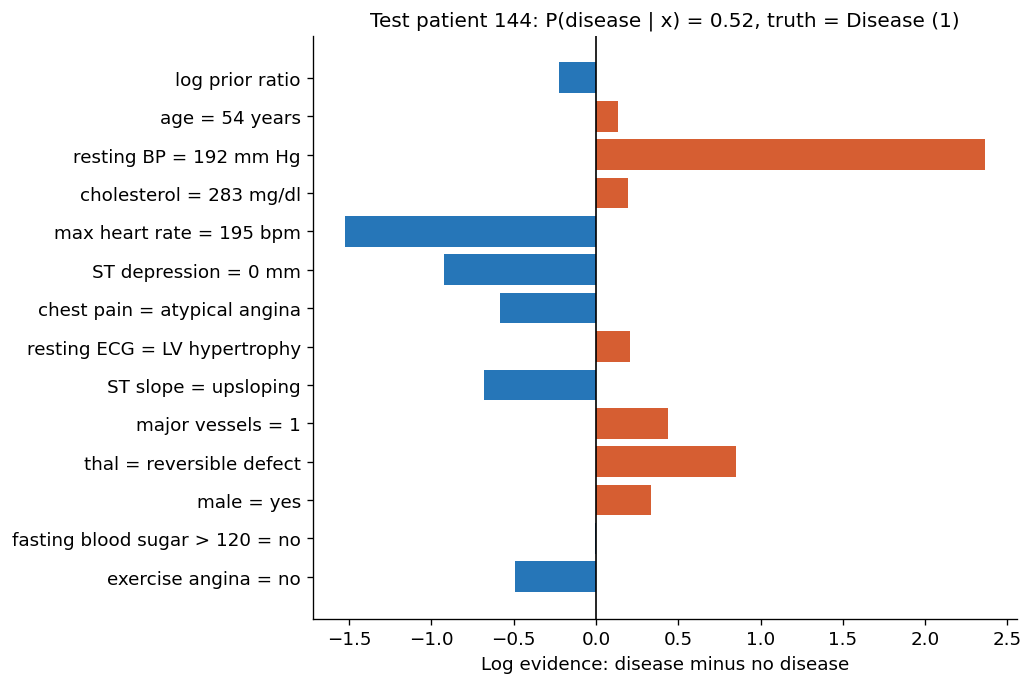

In [13]:
mixed_final = final_models['Mixed NB']  # Refit on train + validation in Part 8.
p_disease = test_probabilities['Mixed NB'][:, 1]
row = test_idx[np.argmin(np.abs(p_disease - 0.5))]
x = X_mixed[row]

# One log-likelihood term per feature and class, shape (2 classes, number of features).
g = mixed_final.gaussian_
cont_terms = norm.logpdf(x[cols_cont], g.theta_, np.sqrt(g.var_))
cat_terms = np.column_stack([log_table[:, int(x[col])] for log_table, col
                             in zip(mixed_final.categorical_.feature_log_prob_, cols_cat)])
q = np.exp(mixed_final.binary_.feature_log_prob_)
bin_terms = np.where(x[cols_bin] == 1, np.log(q), np.log1p(-q))
log_ratio = np.hstack([cont_terms, cat_terms, bin_terms])
log_ratio = log_ratio[1] - log_ratio[0]
prior_ratio = mixed_final.log_prior_[1] - mixed_final.log_prior_[0]

# The bars must add up to the model's log posterior odds.
p_model = mixed_final.predict_proba(x[None])[0, 1]
assert np.isclose(prior_ratio + log_ratio.sum(), np.log(p_model / (1 - p_model)))

labels = ['log prior ratio'] + readable(heart.iloc[row])  # Same X_mixed column order as log_ratio.
values = np.r_[prior_ratio, log_ratio]

fig, ax = plt.subplots(figsize=(8.5, 5.6), layout='constrained')
ax.barh(labels[::-1], values[::-1], color=[COLORS[int(v > 0)] for v in values[::-1]])
ax.axvline(0, color='black', lw=1)
ax.set(xlabel='Log evidence: disease minus no disease',
       title=f'Test patient {row}: P(disease | x) = {p_model:.2f}, '
             f'truth = {CLASS_NAMES[y[row]]}')
plt.show()

#### What should we notice?
- Validation chose **Categorical NB** with 5 features over the mixed model with all 13.
  On the test set the two have the same accuracy, but the mixed model has the higher
  log loss: it is **overconfident**, with many more predictions above 0.95 and more
  confident mistakes.
- Adding features to Naive Bayes is not free. Every feature adds its own log-likelihood
  term, so evidence that several features share is counted several times (question 2),
  and a Gaussian that fits poorly can produce large terms in its tails (question 1).
  Both push the posterior toward 0 or 1.
- Validation made this choice without the test set, and the test set agrees. Most other
  random splits lead to the same choice (question 3).

### Questions for discussion

1. For this patient, resting BP = 192 gives the largest bar, although the two class means of resting BP differ by only about 5 mmHg. Why does a value far in the tails of both Gaussians give such strong evidence? Is it real evidence?
2. Maximum heart rate, ST depression, ST slope, and exercise-induced angina all come from the same exercise test, and here they all point the same way. What does Naive Bayes assume about them, and what does that do to the posterior?
3. The validation set has only 54 patients. Change the two `random_state` values in Part 3 and re-run Parts 3 to 8: do the selected $\alpha$, prior, and model stay the same?
4. Missing a patient with heart disease is worse than a false alarm. Raising the prior $P(\text{disease})$ and lowering the decision threshold (the min-risk rule of Recitation 3) both flag more patients. Why should the two still be kept separate?